In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import LabelEncoder, label_binarize
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    matthews_corrcoef,
    roc_auc_score,
    classification_report,
    confusion_matrix
)


In [2]:
df = pd.read_csv("yeast.csv")
print("First 5 rows:")
df.head()

First 5 rows:


,mcg,gvh,alm,mit,erl,pox,vac,nuc,name
0,0.58,0.61,0.47,0.13,0.5,0.0,0.48,0.22,MIT
1,0.43,0.67,0.48,0.27,0.5,0.0,0.53,0.22,MIT
2,0.64,0.62,0.49,0.15,0.5,0.0,0.53,0.22,MIT
3,0.58,0.44,0.57,0.13,0.5,0.0,0.54,0.22,NUC
4,0.42,0.44,0.48,0.54,0.5,0.0,0.48,0.22,MIT


In [3]:
print("Dataset summary:")
df.info()

print("\nMissing values per column:")
print(df.isnull().sum())

Dataset summary:
<class 'pandas.DataFrame'>
RangeIndex: 1484 entries, 0 to 1483
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   mcg     1484 non-null   float64
 1   gvh     1484 non-null   float64
 2   alm     1484 non-null   float64
 3   mit     1484 non-null   float64
 4   erl     1484 non-null   float64
 5   pox     1484 non-null   float64
 6   vac     1484 non-null   float64
 7   nuc     1484 non-null   float64
 8   name    1484 non-null   str    
dtypes: float64(8), str(1)
memory usage: 104.5 KB

Missing values per column:
mcg     0
gvh     0
alm     0
mit     0
erl     0
pox     0
vac     0
nuc     0
name    0
dtype: int64


In [4]:
target_col = 'name'
feature_cols = [col for col in df.columns if col != target_col]

X = df[feature_cols].values
y_raw = df[target_col].values

print(f"Features list: {feature_cols}")
print(f"Feature matrix shape: {X.shape}")
print(f"Target vector shape: {y_raw.shape}")

Features list: ['mcg', 'gvh', 'alm', 'mit', 'erl', 'pox', 'vac', 'nuc']
Feature matrix shape: (1484, 8)
Target vector shape: (1484,)


In [5]:
# Encode target labels into integer values
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_raw)
classes = np.unique(y)
class_names = label_encoder.classes_

print(f"Classes ({len(classes)} total): {list(class_names)}\n")

# Distribution of original labels
class_counts = df[target_col].value_counts()
print("Class frequency:")
print(class_counts)

Classes (10 total): ['CYT', 'ERL', 'EXC', 'ME1', 'ME2', 'ME3', 'MIT', 'NUC', 'POX', 'VAC']

Class frequency:
name
CYT    463
NUC    429
MIT    244
ME3    163
ME2     51
ME1     44
EXC     35
VAC     30
POX     20
ERL      5
Name: count, dtype: int64


In [6]:

# Stratified K-Fold Cross-Validation

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

fold_history = []

for fold_idx, (train_idx, test_idx) in enumerate(
    skf.split(X, y), start=1
):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=6,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)

    f1_macro = f1_score(
        y_test, y_pred, average="macro", zero_division=0
    )
    f1_weighted = f1_score(
        y_test, y_pred, average="weighted", zero_division=0
    )
    recall_macro = recall_score(
        y_test, y_pred, average="macro", zero_division=0
    )
    mcc = matthews_corrcoef(y_test, y_pred)

    # Align probability columns with all encoded classes
    aligned_proba = np.zeros((len(y_test), len(classes)))

    for j, class_label in enumerate(model.classes_):
        aligned_proba[:, int(class_label)] = y_proba[:, j]

    try:
        auc = roc_auc_score(
            y_test,
            aligned_proba,
            labels=np.arange(len(classes)),
            multi_class="ovr",
            average="macro"
        )
    except ValueError as error:
        print(f"Warning: AUC unavailable in fold {fold_idx}: {error}")
        auc = np.nan

    fold_history.append({
        "Fold": fold_idx,
        "Macro F1": f1_macro,
        "Weighted F1": f1_weighted,
        "Macro Recall": recall_macro,
        "MCC": mcc,
        "ROC-AUC (OvR)": auc
    })

fold_results = pd.DataFrame(fold_history)
display(fold_results)

print("\nCross-validation summary (mean ± standard deviation):")

for metric in [
    "Macro F1", "Weighted F1", "Macro Recall",
    "MCC", "ROC-AUC (OvR)"
]:
    scores = fold_results[metric].dropna()

    if len(scores) > 0:
        print(f"{metric}: {scores.mean():.4f} ± {scores.std():.4f}")
    else:
        print(f"{metric}: unavailable")


,Fold,Macro F1,Weighted F1,Macro Recall,MCC,ROC-AUC (OvR)
0,1,0.394268,0.579942,0.393488,0.490640,0.690699
1,2,0.394924,0.544448,0.411195,0.445596,0.744299
2,3,0.362991,0.501041,0.365921,0.368948,0.694585
3,4,0.420652,0.516309,0.431276,0.424139,0.738605
4,5,0.382138,0.570283,0.399223,0.446684,0.740173



Cross-validation summary (mean ± standard deviation):
Macro F1: 0.3910 ± 0.0210
Weighted F1: 0.5424 ± 0.0338
Macro Recall: 0.4002 ± 0.0240
MCC: 0.4352 ± 0.0442
ROC-AUC (OvR): 0.7217 ± 0.0266


In [7]:
# Cell 7: Summarize the cross-validation results from the previous cell

display(fold_results)

print("\\nMean ± Standard Deviation")

for metric in [
    "Macro F1",
    "Weighted F1",
    "MCC",
    "Macro Recall",
    "ROC-AUC (OvR)"
]:
    scores = fold_results[metric].dropna()
    if len(scores) > 0:
        print(f"{metric}: {scores.mean():.4f} ± {scores.std():.4f}")
    else:
        print(f"{metric}: unavailable")


,Fold,Macro F1,Weighted F1,Macro Recall,MCC,ROC-AUC (OvR)
0,1,0.394268,0.579942,0.393488,0.490640,0.690699
1,2,0.394924,0.544448,0.411195,0.445596,0.744299
2,3,0.362991,0.501041,0.365921,0.368948,0.694585
3,4,0.420652,0.516309,0.431276,0.424139,0.738605
4,5,0.382138,0.570283,0.399223,0.446684,0.740173


\nMean ± Standard Deviation
Macro F1: 0.3910 ± 0.0210
Weighted F1: 0.5424 ± 0.0338
MCC: 0.4352 ± 0.0442
Macro Recall: 0.4002 ± 0.0240
ROC-AUC (OvR): 0.7217 ± 0.0266


In [8]:
# Optional: display the per-fold results with Fold as the index

fold_df = fold_results.set_index("Fold")
display(fold_df)


,Macro F1,Weighted F1,Macro Recall,MCC,ROC-AUC (OvR)
Fold,,,,,
1,0.394268,0.579942,0.393488,0.490640,0.690699
2,0.394924,0.544448,0.411195,0.445596,0.744299
3,0.362991,0.501041,0.365921,0.368948,0.694585
4,0.420652,0.516309,0.431276,0.424139,0.738605
5,0.382138,0.570283,0.399223,0.446684,0.740173


In [9]:
# Separate 80/20 stratified holdout evaluation

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

eval_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=6,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)
eval_model.fit(X_train, y_train)

y_test_pred = eval_model.predict(X_test)

print("Classification Report on 20% Holdout Test Set:\\n")
print(classification_report(
    y_test,
    y_test_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    zero_division=0
))

print(f"Holdout accuracy: {accuracy_score(y_test, y_test_pred):.4f}")
print(f"Holdout MCC: {matthews_corrcoef(y_test, y_test_pred):.4f}")


Classification Report on 20% Holdout Test Set:\n
              precision    recall  f1-score   support

         CYT       0.47      0.77      0.59        93
         ERL       0.00      0.00      0.00         1
         EXC       0.20      0.14      0.17         7
         ME1       0.60      0.67      0.63         9
         ME2       0.43      0.30      0.35        10
         ME3       0.79      0.81      0.80        32
         MIT       0.68      0.57      0.62        49
         NUC       0.56      0.31      0.40        86
         POX       1.00      0.25      0.40         4
         VAC       0.00      0.00      0.00         6

    accuracy                           0.55       297
   macro avg       0.47      0.38      0.40       297
weighted avg       0.56      0.55      0.53       297

Holdout accuracy: 0.5522
Holdout MCC: 0.4246


### Holdout evaluation note

The separate 80/20 holdout evaluation is performed in the preceding code cell. It is supplementary to the five-fold cross-validation results; the cross-validation summary is the primary robustness evaluation.

Feature importances:


,Feature,Importance
2,alm,0.282904
0,mcg,0.213949
3,mit,0.185317
1,gvh,0.154538
7,nuc,0.140827
6,vac,0.022466
5,pox,0.000000
4,erl,0.000000


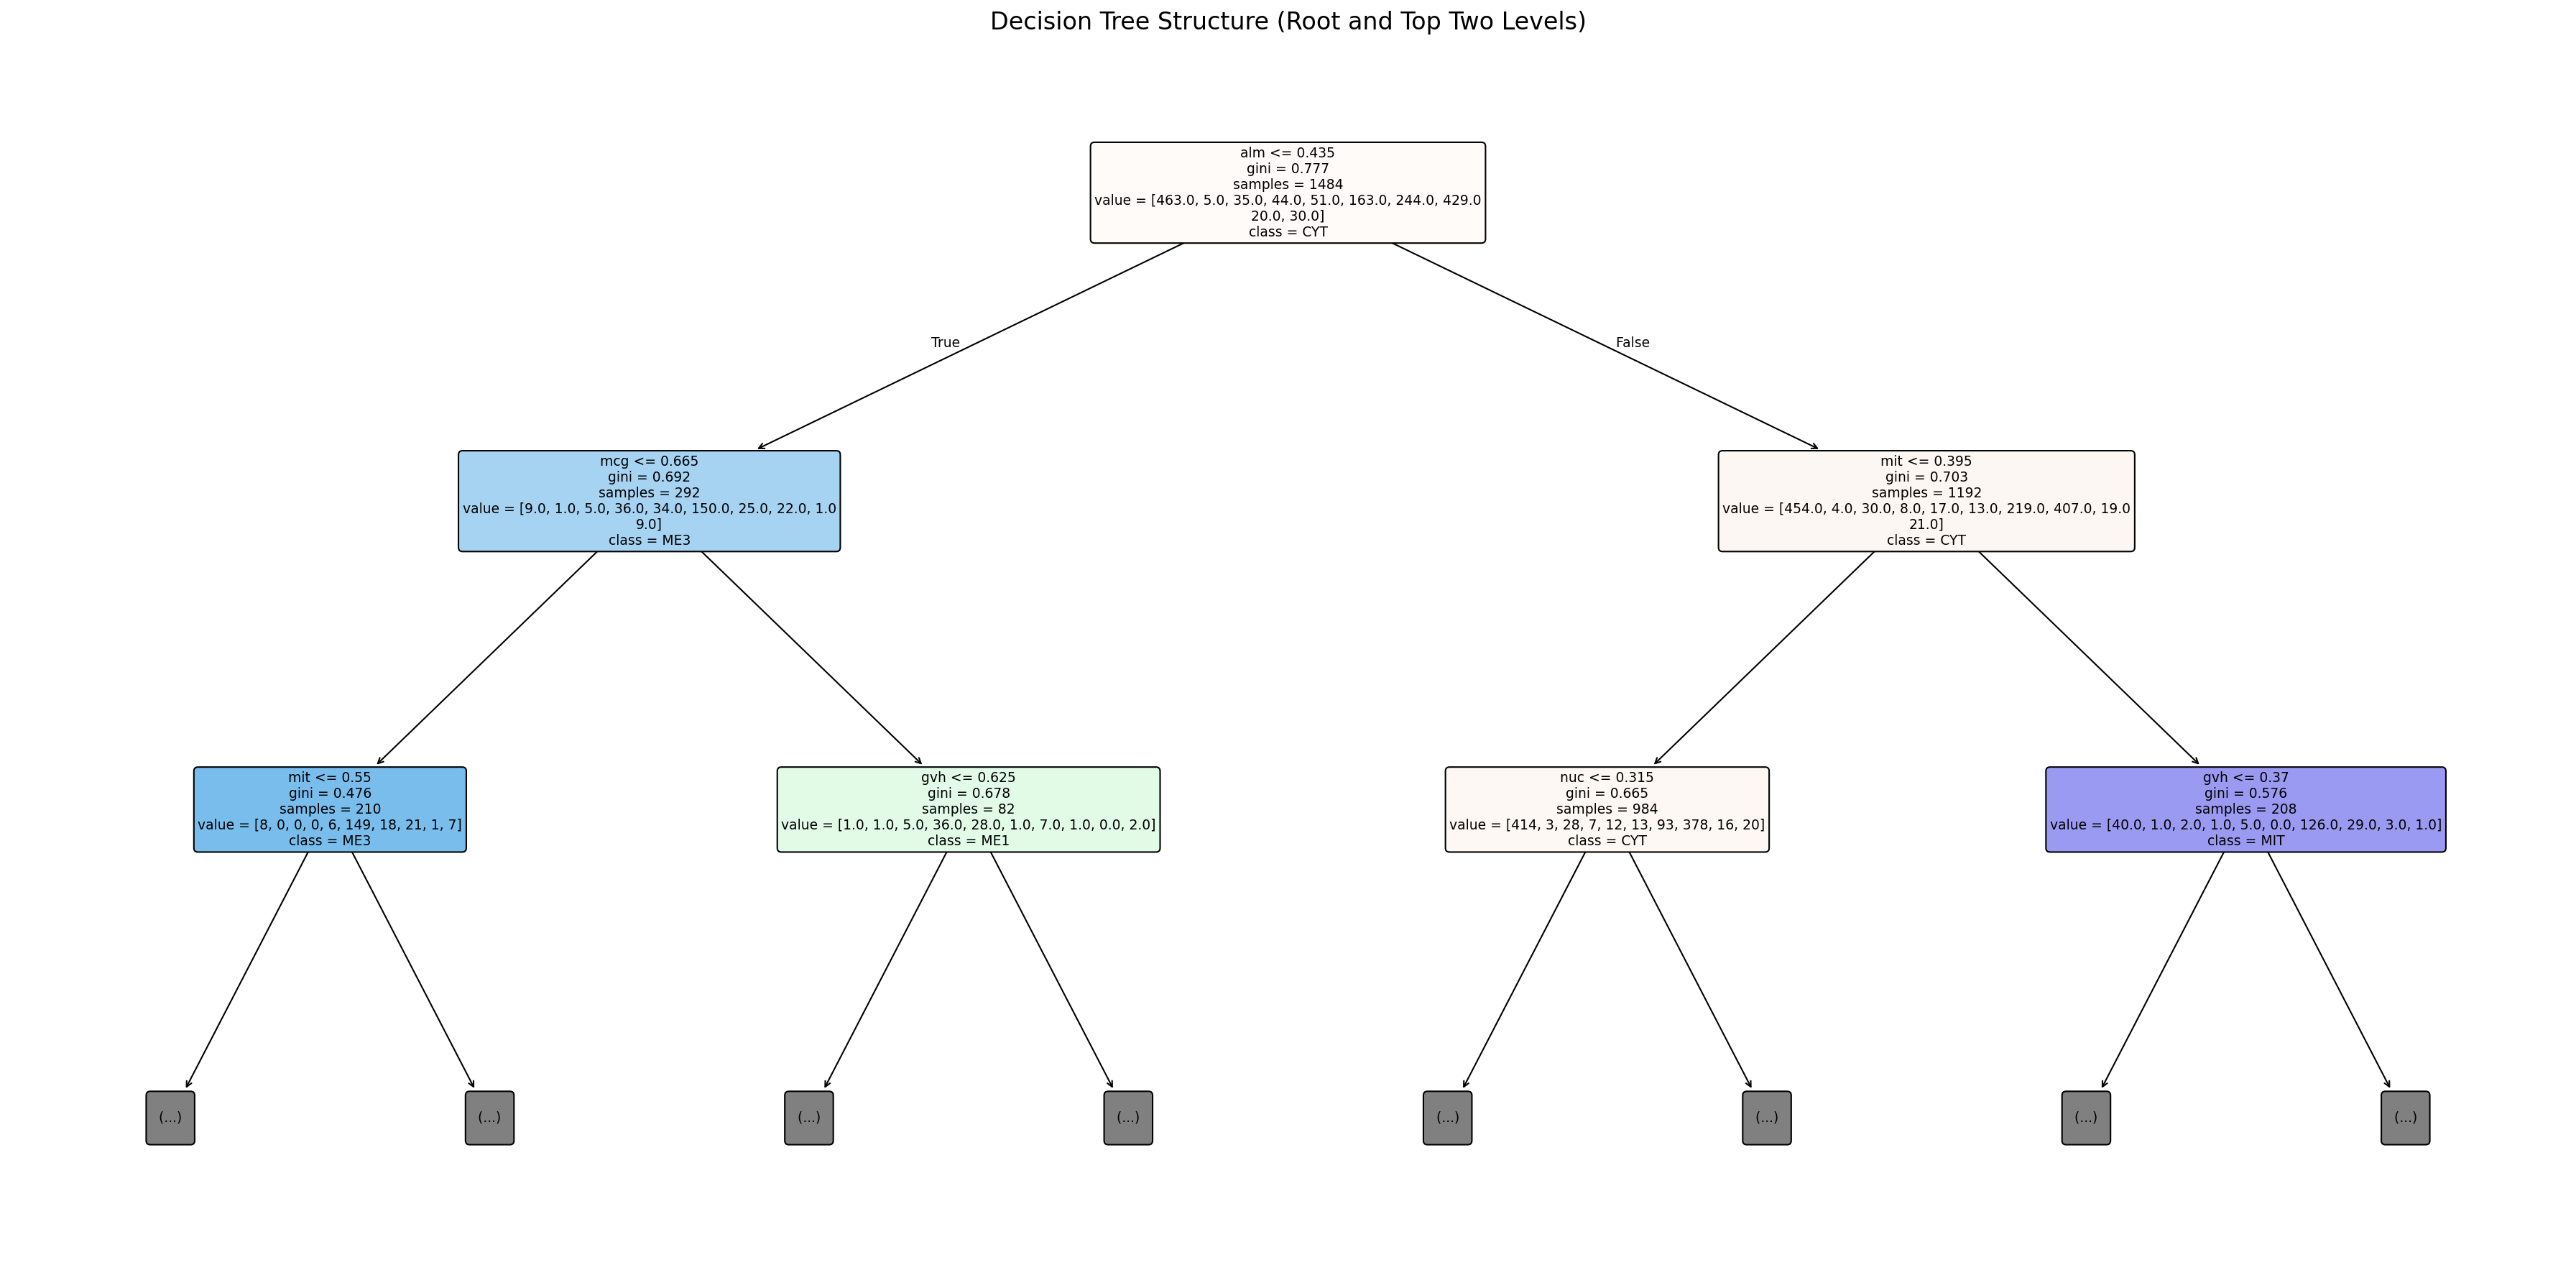

In [10]:
# Fit a final Decision Tree on all available data for visualization

final_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=6,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)
final_model.fit(X, y)

# Feature importance
importance_df = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": final_model.feature_importances_
}).sort_values("Importance", ascending=False)

print("Feature importances:")
display(importance_df)

# Visualize the upper levels of the fitted tree
plt.figure(figsize=(24, 12), dpi=150)

plot_tree(
    final_model,
    feature_names=feature_cols,
    class_names=[str(c) for c in class_names],
    max_depth=2,
    filled=True,
    rounded=True,
    impurity=True,
    fontsize=9
)

plt.title("Decision Tree Structure (Root and Top Two Levels)", fontsize=16)
plt.tight_layout()
plt.savefig("decision_tree.png", dpi=300, bbox_inches="tight")
plt.show()


## Conclusion

A Decision Tree classifier was implemented using scikit-learn to predict protein localization sites from eight numerical features in the yeast dataset. The dataset contains 1,484 samples across ten localization classes.

The model was evaluated using five-fold Stratified Cross-Validation with Macro F1, Weighted F1, Macro Recall, Matthews Correlation Coefficient (MCC), and multiclass ROC-AUC using a One-vs-Rest approach.

Use the cross-validation summary printed above to report the final mean and standard deviation for each metric. Macro-averaged metrics are particularly useful here because the class distribution is imbalanced. The ERL class has only five samples, so its individual performance estimates are especially uncertain.

Feature importance from the final fitted tree is displayed above and helps identify which numerical features contribute most to its splits.

Overall, the notebook demonstrates multiclass classification, stratified cross-validation, performance evaluation, and model interpretation. Performance on underrepresented classes remains a limitation.